<sub>**The Annotated ML Handbook** · Part V: scikit-learn</sub>

# Chapter 24: Unsupervised learning: clustering and dimensionality reduction

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-5-scikit-learn/24-sklearn-unsupervised.ipynb)

Companion code for the chapter. Every example from the book is here, in order, ready to run. The line-by-line explanations, definitions and discussion are in the book.

Run the setup cell first, then run the cells from top to bottom.

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

## 24.1 k-means clustering · *Beginner*

**Clustering synthetic blobs**

inertia (within-cluster sum of squares): 20.89
cluster sizes: [125 125 125 125]


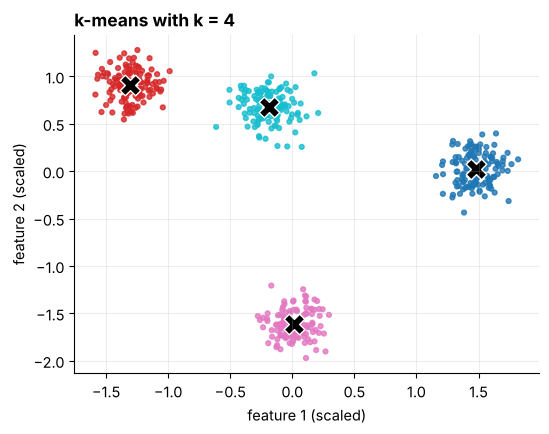

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

X, y_true = make_blobs(n_samples=500, centers=4, cluster_std=0.9, random_state=7)
Xs = StandardScaler().fit_transform(X)
km = KMeans(n_clusters=4, n_init=10, random_state=0)
labels = km.fit_predict(Xs)
print("inertia (within-cluster sum of squares):", round(km.inertia_, 2))
print("cluster sizes:", np.bincount(labels))
fig, ax = plt.subplots(figsize=(6, 4.4))
ax.scatter(Xs[:, 0], Xs[:, 1], c=labels, cmap="tab10", s=12, alpha=0.8)
ax.scatter(*km.cluster_centers_.T, marker="X", s=220, c="black", edgecolor="white")
ax.set(title="k-means with k = 4", xlabel="feature 1 (scaled)", ylabel="feature 2 (scaled)")
plt.show()

### 24.1.1 Choosing k: elbow and silhouette · *Intermediate*

**Two diagnostics side by side**

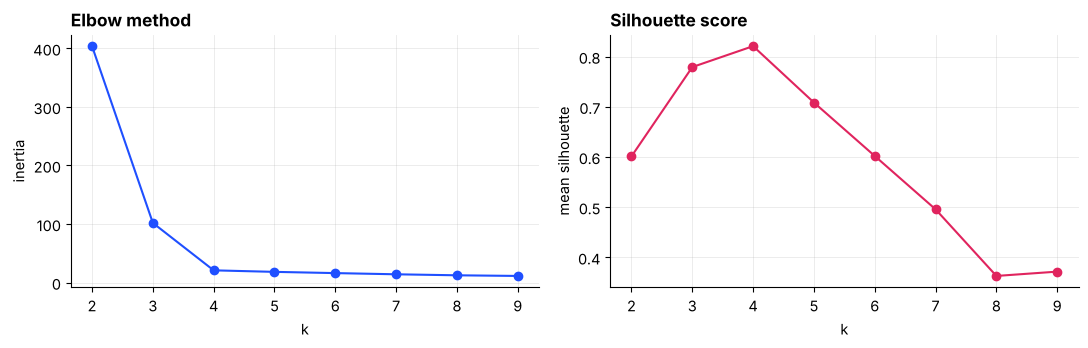

best k by silhouette: 4


In [3]:
from sklearn.metrics import silhouette_score

ks = range(2, 10)
inertias, sils = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    inertias.append(m.inertia_)
    sils.append(silhouette_score(Xs, m.labels_))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(ks, inertias, marker="o"); axes[0].set(title="Elbow method", xlabel="k", ylabel="inertia")
axes[1].plot(ks, sils, marker="o", color="#e0245e"); axes[1].set(title="Silhouette score", xlabel="k", ylabel="mean silhouette")
plt.tight_layout()
plt.show()
print("best k by silhouette:", list(ks)[int(np.argmax(sils))])

## 24.2 Other clustering algorithms · *Intermediate*

**When k-means fails: non-spherical shapes**

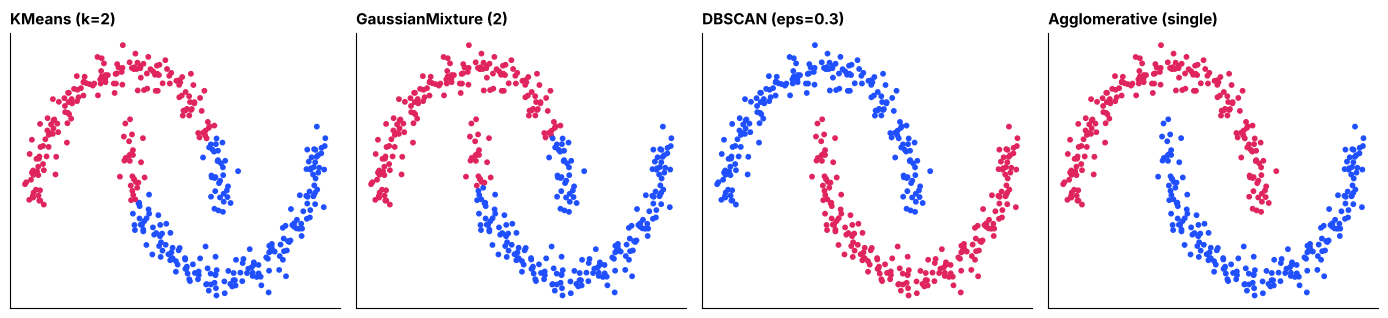

In [4]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture

Xm, _ = make_moons(n_samples=400, noise=0.07, random_state=0)
Xm = StandardScaler().fit_transform(Xm)
algos = {
    "KMeans (k=2)": KMeans(n_clusters=2, n_init=10, random_state=0),
    "GaussianMixture (2)": GaussianMixture(n_components=2, random_state=0),
    "DBSCAN (eps=0.3)": DBSCAN(eps=0.3, min_samples=5),
    "Agglomerative (single)": AgglomerativeClustering(n_clusters=2, linkage="single"),
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
for ax, (name, algo) in zip(axes, algos.items()):
    lab = algo.fit_predict(Xm)
    colors = np.where(lab == -1, "lightgrey", np.array(["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00"])[lab % 4])
    ax.scatter(Xm[:, 0], Xm[:, 1], c=colors, s=10)
    ax.set_title(name, fontsize=11); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

### 24.2.1 Evaluating clusters when labels exist · *Intermediate*

**External and internal validation**

In [5]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
print("ARI:", round(adjusted_rand_score(y_true, labels), 3))
print("NMI:", round(normalized_mutual_info_score(y_true, labels), 3))
print("silhouette:", round(silhouette_score(Xs, labels), 3))

ARI: 1.0
NMI: 1.0
silhouette: 0.821


## 24.3 Principal component analysis (PCA) · *Intermediate*

**PCA on the breast-cancer features**

variance explained by PC1, PC2: [0.443 0.19 ]
components for 95% variance: 10


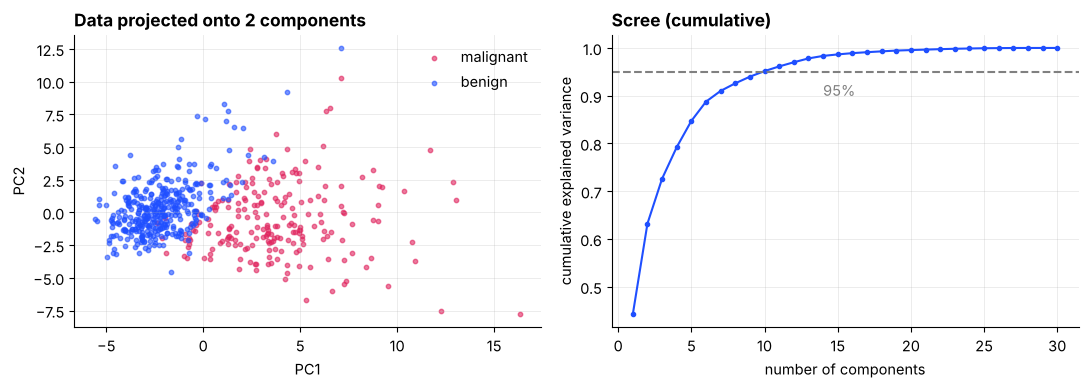

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

bc = load_breast_cancer()
pca_pipe = make_pipeline(StandardScaler(), PCA())
Z = pca_pipe.fit_transform(bc.data)
pca = pca_pipe.named_steps["pca"]
print("variance explained by PC1, PC2:", pca.explained_variance_ratio_[:2].round(3))
print("components for 95% variance:", np.searchsorted(np.cumsum(pca.explained_variance_ratio_), 0.95) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for cls, name, c in [(0, "malignant", "#e0245e"), (1, "benign", "#1f4fff")]:
    axes[0].scatter(Z[bc.target == cls, 0], Z[bc.target == cls, 1], s=10, alpha=0.6, label=name, color=c)
axes[0].set(xlabel="PC1", ylabel="PC2", title="Data projected onto 2 components")
axes[0].legend()
axes[1].plot(range(1, 31), np.cumsum(pca.explained_variance_ratio_), marker="o", ms=3)
axes[1].axhline(0.95, ls="--", color="grey"); axes[1].text(14, 0.9, "95%", color="grey")
axes[1].set(xlabel="number of components", ylabel="cumulative explained variance", title="Scree (cumulative)")
plt.tight_layout()
plt.show()

**What does each component mean? (loadings)**

In [7]:
loadings = pd.DataFrame(pca.components_[:2].T, index=bc.feature_names, columns=["PC1", "PC2"])
print(loadings["PC1"].abs().sort_values(ascending=False).head(5).round(3))

mean concave points     0.261
mean concavity          0.258
worst concave points    0.251
mean compactness        0.239
worst perimeter         0.237
Name: PC1, dtype: float64


**PCA as a preprocessing step**

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
pipe = make_pipeline(StandardScaler(), PCA(n_components=0.95), LogisticRegression(max_iter=1000))
print("CV accuracy with PCA:", cross_val_score(pipe, bc.data, bc.target, cv=5).mean().round(4))

CV accuracy with PCA: 0.9807


## 24.4 t-SNE and UMAP for visualisation · *Advanced*

**t-SNE on 8x8 handwritten digits**

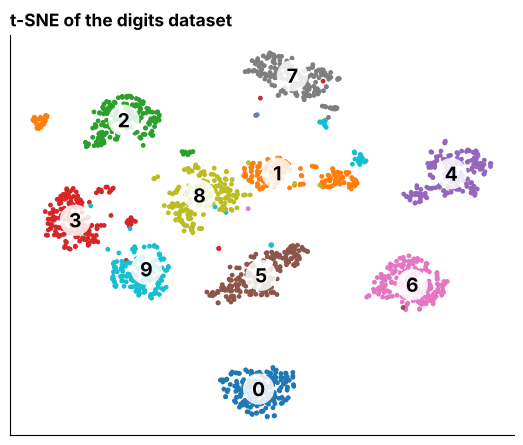

In [9]:
from sklearn.datasets import load_digits
from sklearn.manifold import TSNE

digits = load_digits()
emb = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(digits.data)
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sc = ax.scatter(emb[:, 0], emb[:, 1], c=digits.target, cmap="tab10", s=6)
for d in range(10):
    cx, cy = np.median(emb[digits.target == d], axis=0)
    ax.text(cx, cy, str(d), fontsize=14, fontweight="bold", ha="center", va="center",
            bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec="none", alpha=0.85))
ax.set(title="t-SNE of the digits dataset", xticks=[], yticks=[])
ax.grid(False)
plt.show()

## 24.5 Anomaly detection · *Intermediate*

**Isolation Forest flags unusual samples**

In [10]:
from sklearn.ensemble import IsolationForest
rng = np.random.default_rng(0)
normal = rng.normal(0, 1, (300, 2))
odd = rng.uniform(-6, 6, (15, 2))
Xa = np.vstack([normal, odd])
iso = IsolationForest(contamination=0.05, random_state=0).fit(Xa)
flag = iso.predict(Xa)
print("flagged:", (flag == -1).sum(), "| of the true anomalies caught:", (flag[-15:] == -1).sum(), "/ 15")

flagged: 16 | of the true anomalies caught: 12 / 15


## Try it yourself

1. Cluster the insurance customers (scaled `age`, `bmi`, `charges`) with k-means and profile each cluster with `groupby(labels).mean()`.
2. Run PCA on the wine dataset and plot the first two components coloured by cultivar.
3. Compare t-SNE maps of the digits with perplexity 5, 30 and 100.

Worked solutions: [solutions-parts-5-8.ipynb](../../solutions/solutions-parts-5-8.ipynb), section *Chapter 24*.